# Лабораторна робота №7. Глибинне навчання для Time Series
Дані: виробництво електроенергії. Порівнюємо три типи нейромереж — Dense (MLP), LSTM і GRU (група вимог 3).

## 1. Завантаження та дослідження даних

In [1]:
import pandas as pd
df = pd.read_csv("../lab5/archive/Electric_Production.csv")

In [2]:
import sys
import os
sys.path.append(os.path.abspath('..'))

from lab4.time_series_analysis.decomposition import *

In [3]:
df.columns = ['date', 'consumption']

In [4]:
df['date'] = pd.to_datetime(df['date'])

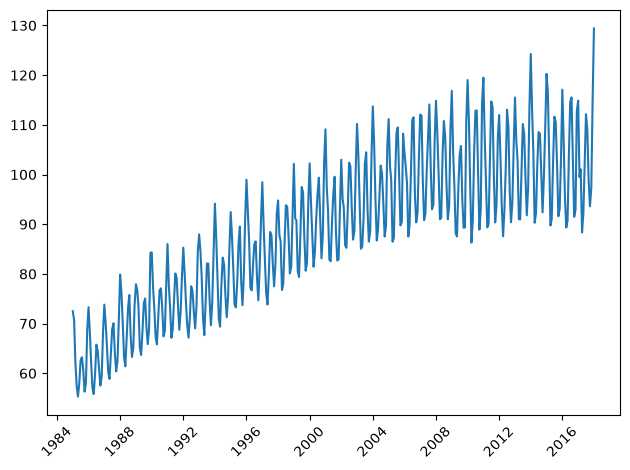

In [5]:
import matplotlib.pyplot as plt
plt.plot(df['date'], df['consumption'])
plt.xticks(rotation=45)
plt.tight_layout()

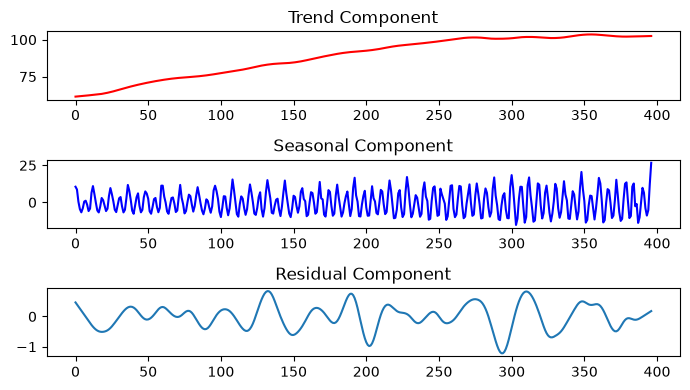

In [6]:
Y = df['consumption']
decomposed = decompose(Y, 12, 3, True)
plot_decomposition(decomposed)

Властивості
кількість елементів вбірки= 397
матиматичне сподівання ВВ= -0.43903892649852594
дисперсія ВВ = 61.65867176660544
СКВ ВВ= 7.8523035961815335 



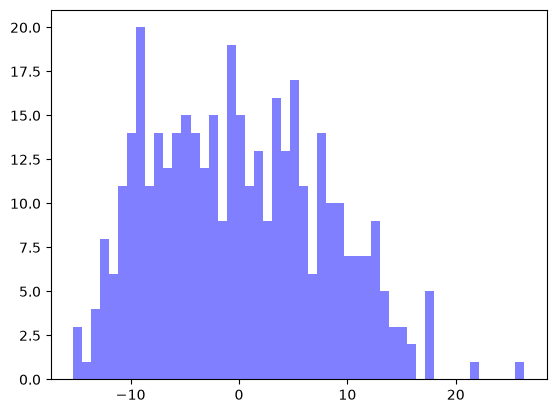

In [7]:
from lab4.time_series_analysis.stat_analysis import *
ts_stat_characteristics(Y, "Властивості")

Results of Dickey-Fuller Test_1:
ADF Statistic: -2.256990350047235
p-value: 0.1862146911658712
Critical Values:
   1%: -3.4476305904172904
   5%: -2.869155980820355
   10%: -2.570827146203181


/home/budulka/Documents/TimeSeriesLabs/lab4/time_series_analysis/stat_analysis.py:69: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


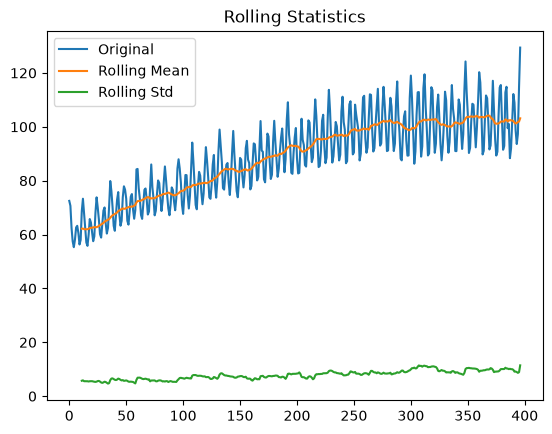

In [8]:
dfuller_test_1(Y)

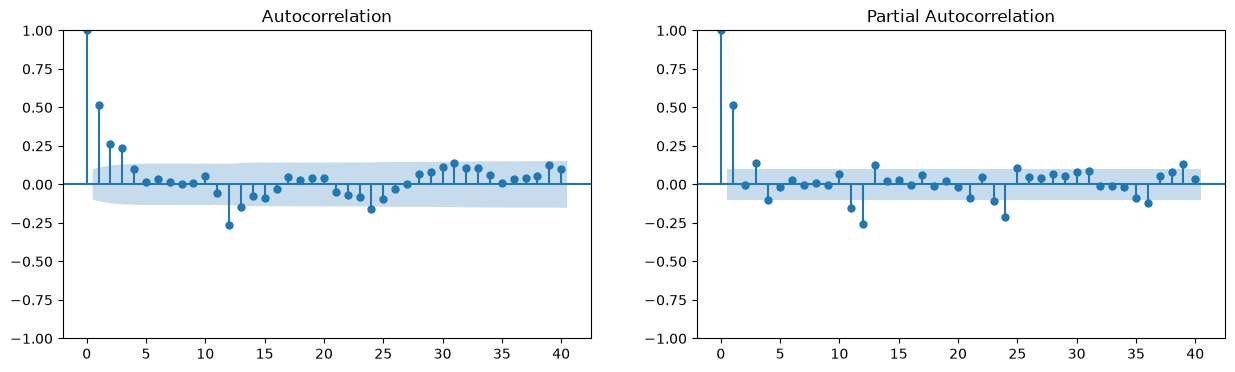

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

stationary_series = df['consumption'].diff(12).dropna()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(stationary_series, ax=axes[0], lags=40)
plot_pacf(stationary_series, ax=axes[1], lags=40)
plt.show()

## Віконне (windowed) представлення ряду



In [10]:
import numpy as np

def make_windows(series, window_size):
    X, y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i:i + window_size])
        y.append(series[i + window_size])
    return np.array(X), np.array(y)

window_size = 12  # річна сезонність для місячних даних
series = df['consumption'].values.astype(np.float32)

X, Y = make_windows(series, window_size)
print("X shape:", X.shape, " Y shape:", Y.shape)

X shape: (385, 12)  Y shape: (385,)


In [11]:
from sklearn.model_selection import train_test_split

### Послідовний спліт



In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.1, shuffle=False)

### Масштабування
Нормуємо дані в [−1, 1]. Scaler навчаємо лише на train, щоб не було витоку даних з тесту.

In [13]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(-1, 1))
scaler.fit(y_train.reshape(-1, 1))

X_train = scaler.transform(X_train.reshape(-1, 1)).reshape(X_train.shape)
X_test = scaler.transform(X_test.reshape(-1, 1)).reshape(X_test.shape)

y_train = scaler.transform(y_train.reshape(-1, 1))
y_test = scaler.transform(y_test.reshape(-1, 1))

Додатково виділяємо валідаційну вибірку (10% від train) для early stopping.

In [14]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, shuffle=False)

## 2. Навчання та оцінювання
Функція втрат — MSE (стандартна для регресії). Оптимізатор Adam, early stopping за val_loss. Метрики: MAE, RMSE, MAPE, R².

In [15]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

I0000 00:00:1789410683.190977  630033 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789410683.191391  630033 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789410683.224605  630033 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789410684.358157  630033 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [16]:
class TestLossCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_test, y_test):
        super().__init__()
        self.X_test = X_test
        self.y_test = y_test
        self.test_losses = []

    def on_epoch_end(self, epoch, logs=None):
        test_loss = self.model.evaluate(self.X_test, self.y_test, verbose=0)
        self.test_losses.append(test_loss)

In [17]:
def train_model(model, X_train, y_train, X_val, y_val, X_test, y_test, epochs=100, batch_size=32):
    optimizer = tf.keras.optimizers.Adam()
    model.compile(loss='mean_squared_error', optimizer=optimizer)

    test_loss_cb = TestLossCallback(X_test, y_test)
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[test_loss_cb, early_stop],
        verbose=1
    )

    print(f"Реально пройдено епох: {len(history.history['loss'])}")

    return history, test_loss_cb

In [18]:
def evaluate_and_plot(model, history, test_loss_cb, X_test, y_test, scaler):
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['loss'], label='Train loss')
    plt.plot(history.history['val_loss'], label='Validation loss')
    plt.plot(test_loss_cb.test_losses, label='Test loss')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.title('Динаміка функції втрат')
    plt.legend()
    plt.grid(True)
    plt.show()

    predicted = model.predict(X_test)

    y_test_inv = scaler.inverse_transform(y_test)
    predicted_inv = scaler.inverse_transform(predicted)

    mae = mean_absolute_error(y_test_inv, predicted_inv)
    rmse = np.sqrt(mean_squared_error(y_test_inv, predicted_inv))
    r2 = r2_score(y_test_inv, predicted_inv)
    mape = np.mean(np.abs((y_test_inv - predicted_inv) / y_test_inv)) * 100

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAPE: {mape:.2f}%")
    print(f"R²: {r2:.4f}")

    plt.figure(figsize=(15, 5))
    plt.plot(y_test_inv, color='blue', label='Real')
    plt.plot(predicted_inv, color='red', label='Predicted')
    plt.title('Реальні vs Прогнозовані значення (тестовий набір)')
    plt.legend()
    plt.show()

    return y_test_inv, predicted_inv

## Dense-модель

Dense-модель отримує ціле вікно як плоский вектор ознак
(`input_dim = window_size`).

In [19]:
class DenseModel(tf.keras.Sequential):
    def __init__(self, n_neurons, input_dim, sigma=1):
        super(DenseModel, self).__init__()

        weight_initializer = tf.keras.initializers.VarianceScaling(
            seed=7, scale=sigma, mode="fan_avg", distribution="uniform"
        )
        bias_initializer = tf.zeros_initializer()

        self.add(tf.keras.Input(shape=(input_dim,), name="input"))
        for i, n in enumerate(n_neurons):
            self.add(tf.keras.layers.Dense(
                n, activation=tf.nn.relu,
                kernel_initializer=weight_initializer,
                bias_initializer=bias_initializer,
                name=f"dense_{i+1}"
            ))
        self.add(tf.keras.layers.Dense(
            1, kernel_initializer=weight_initializer,
            bias_initializer=bias_initializer,
            name="output"
        ))

E0000 00:00:1789410684.669974  630033 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1789410684.693378  630033 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1212 - val_loss: 0.0267
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0243 - val_loss: 0.0198
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0133 - val_loss: 0.0176
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0090 - val_loss: 0.0113
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0064 - val_loss: 0.0102
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0057 - val_loss: 0.0099
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0053 - val_loss: 0.0094
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0050 - val_loss: 0.0094
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0052 - val_loss: 0.0092
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0049 - val_loss: 0.0092
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0044 - val_loss: 0.0093
Epoch 12/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

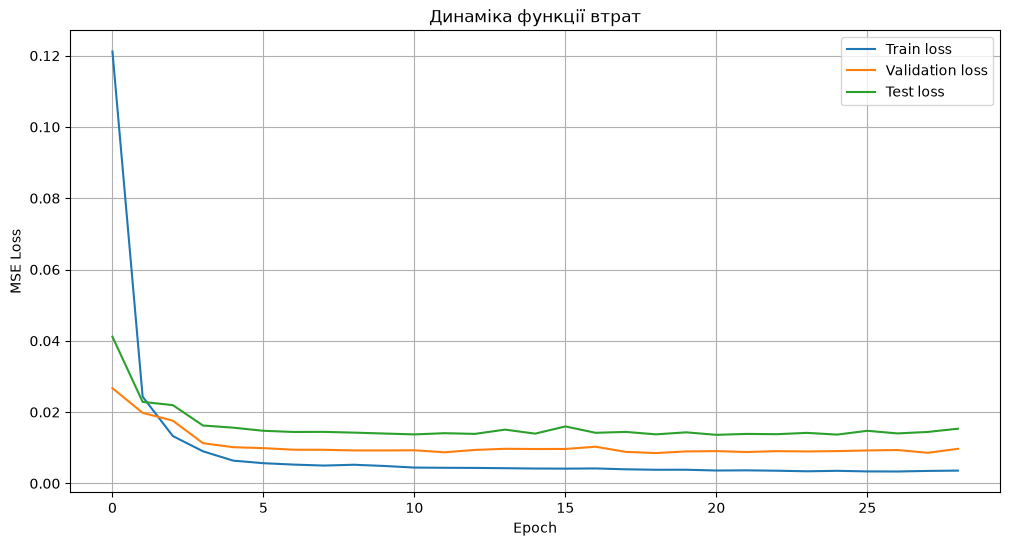

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
MAE: 2.8229
RMSE: 4.0132
MAPE: 2.64%
R²: 0.8437


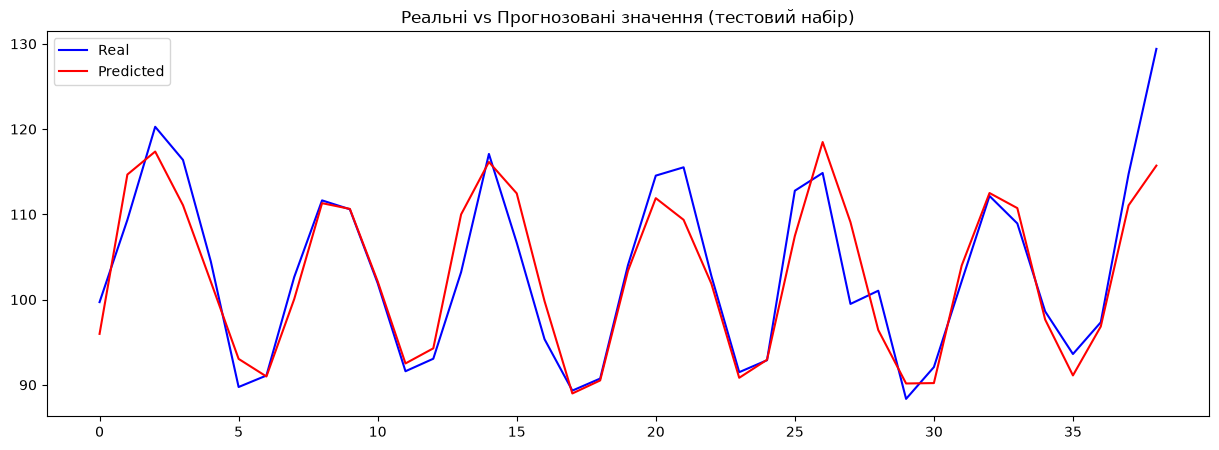

In [20]:
n_neurons = [128, 64, 32]
sigma = 1
epochs = 100
batch_size = 32

dense_model = DenseModel(n_neurons=n_neurons, input_dim=X_train.shape[1], sigma=sigma)
history, test_loss_cb = train_model(dense_model, X_train, y_train, X_val, y_val, X_test, y_test, epochs, batch_size)
y_test_inv, predicted_inv = evaluate_and_plot(dense_model, history, test_loss_cb, X_test, y_test, scaler)

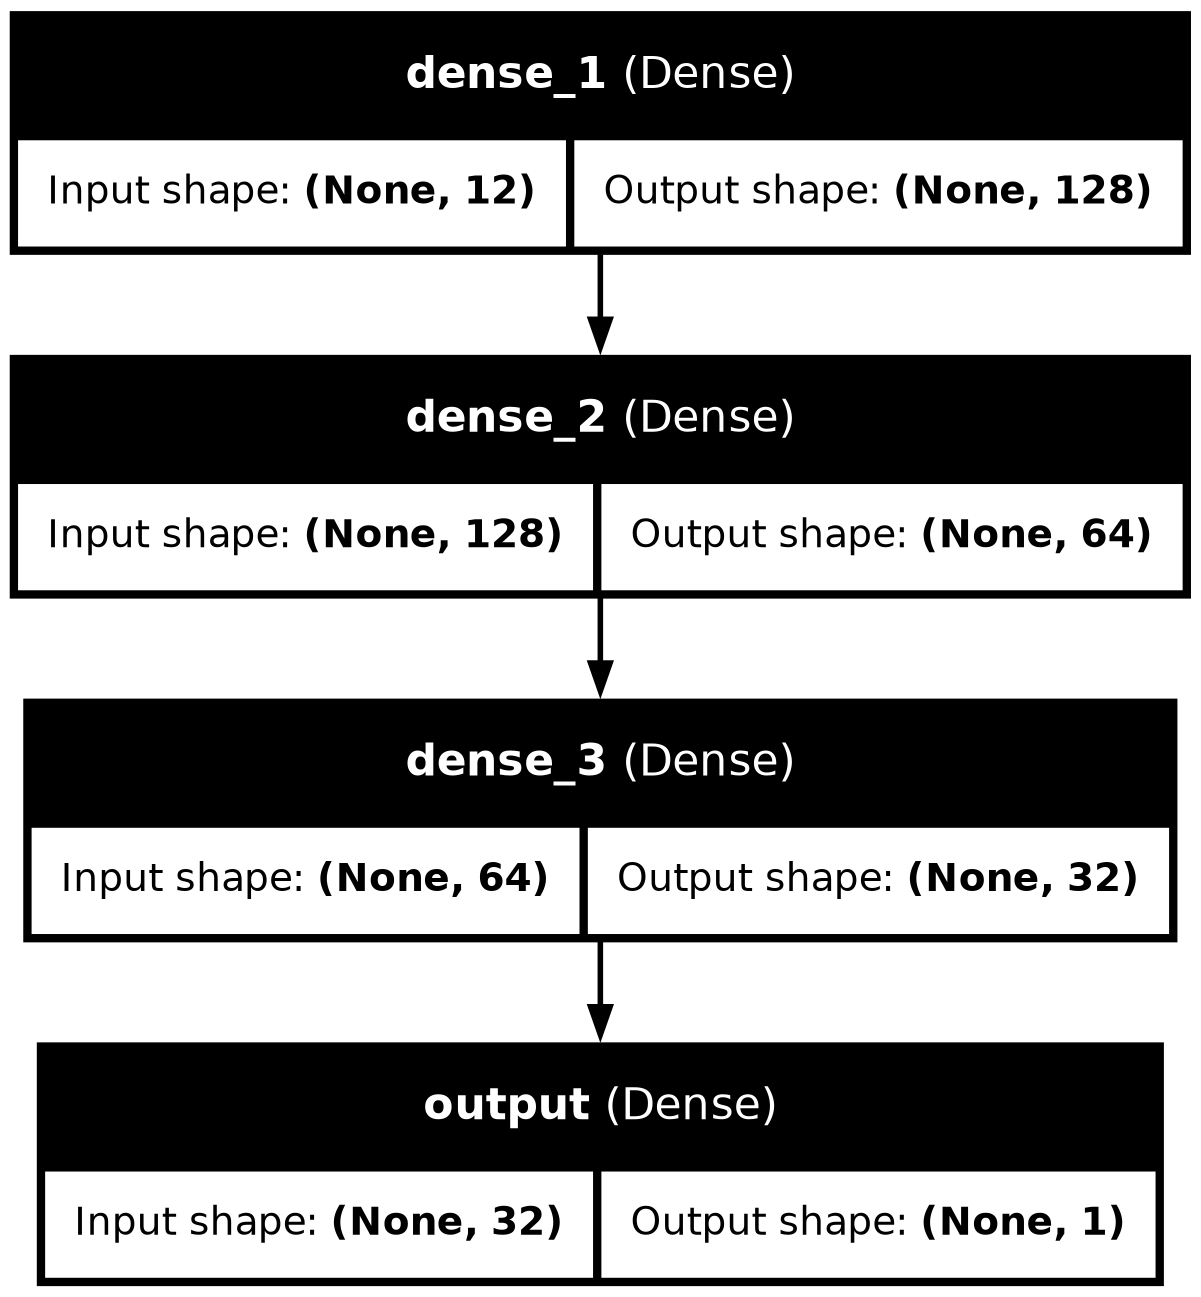

In [21]:
from IPython.display import Image

tf.keras.utils.plot_model(
    dense_model,
    to_file='dense_architecture.png',
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True
)
Image('dense_architecture.png')

## Послідовна форма входу для LSTM/GRU



In [22]:
X_train_seq = X_train.reshape((X_train.shape[0], X_train.shape[1], 1)).astype(np.float32)
X_val_seq = X_val.reshape((X_val.shape[0], X_val.shape[1], 1)).astype(np.float32)
X_test_seq = X_test.reshape((X_test.shape[0], X_test.shape[1], 1)).astype(np.float32)

## LSTM-модель
LSTM має вентилі пам'яті й враховує порядок значень у вікні. Архітектура: 128–64–32 + вихідний шар.

In [23]:
class LSTMModel(tf.keras.Sequential):
    def __init__(self, n_neurons, input_dim, sigma=1):
        super(LSTMModel, self).__init__()

        weight_initializer = tf.keras.initializers.VarianceScaling(
            seed=7, scale=sigma, mode="fan_avg", distribution="uniform"
        )
        bias_initializer = tf.zeros_initializer()

        self.add(tf.keras.Input(shape=(input_dim, 1), name="input"))

        for i, n in enumerate(n_neurons):
            return_sequences = i < len(n_neurons) - 1
            self.add(tf.keras.layers.LSTM(
                n,
                return_sequences=return_sequences,
                kernel_initializer=weight_initializer,
                bias_initializer=bias_initializer,
                name=f"lstm_{i}"
            ))

        self.add(tf.keras.layers.Dense(
            1,
            kernel_initializer=weight_initializer,
            bias_initializer=bias_initializer,
            name="output"
        ))

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0936 - val_loss: 0.0659
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0563 - val_loss: 0.0687
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0488 - val_loss: 0.0653
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0503 - val_loss: 0.0654
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0475 - val_loss: 0.0647
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0458 - val_loss: 0.0636
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0447 - val_loss: 0.0620
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0433 - val_loss: 0.0610
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0431 - val_loss: 0.0592
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0423 - val_loss: 0.0579
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0422 - val_loss: 0.0556
Epoch 12/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

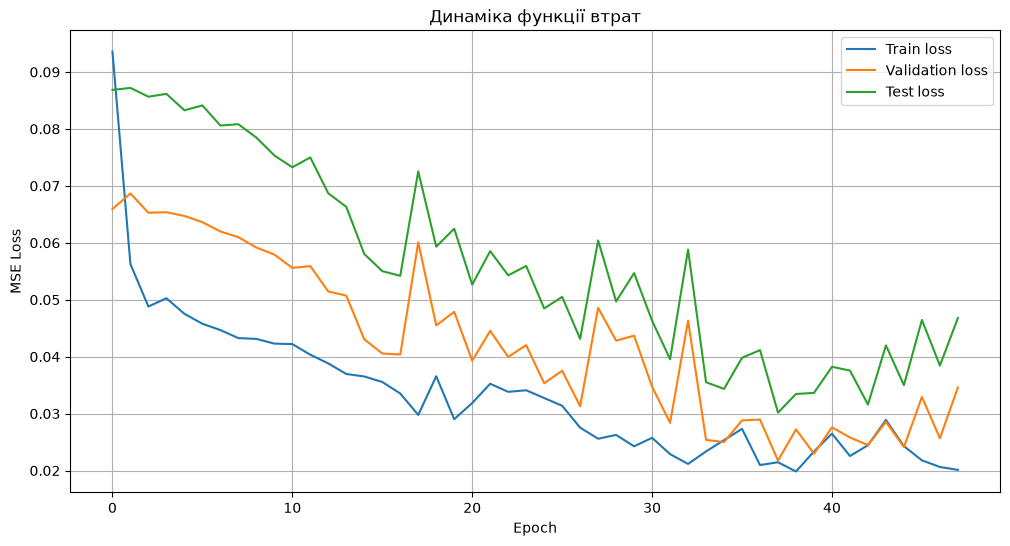

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step
MAE: 4.6586
RMSE: 5.9439
MAPE: 4.36%
R²: 0.6571


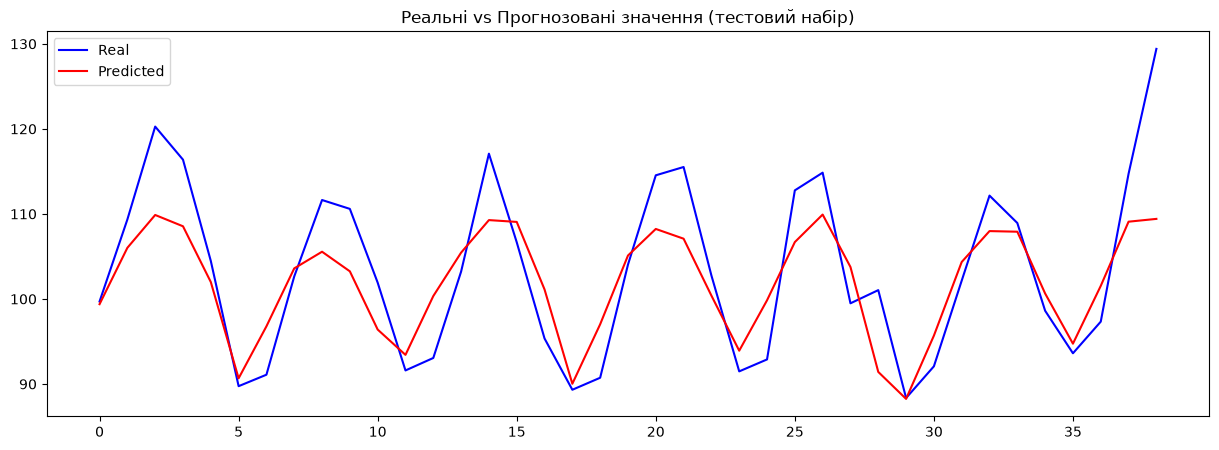

In [24]:
n_neurons = [128, 64, 32]
sigma = 1
epochs = 100
batch_size = 32

lstm_model = LSTMModel(n_neurons=n_neurons, input_dim=X_train_seq.shape[1], sigma=sigma)
history, test_loss_cb = train_model(lstm_model, X_train_seq, y_train, X_val_seq, y_val, X_test_seq, y_test, epochs, batch_size)
y_test_inv, predicted_inv = evaluate_and_plot(lstm_model, history, test_loss_cb, X_test_seq, y_test, scaler)

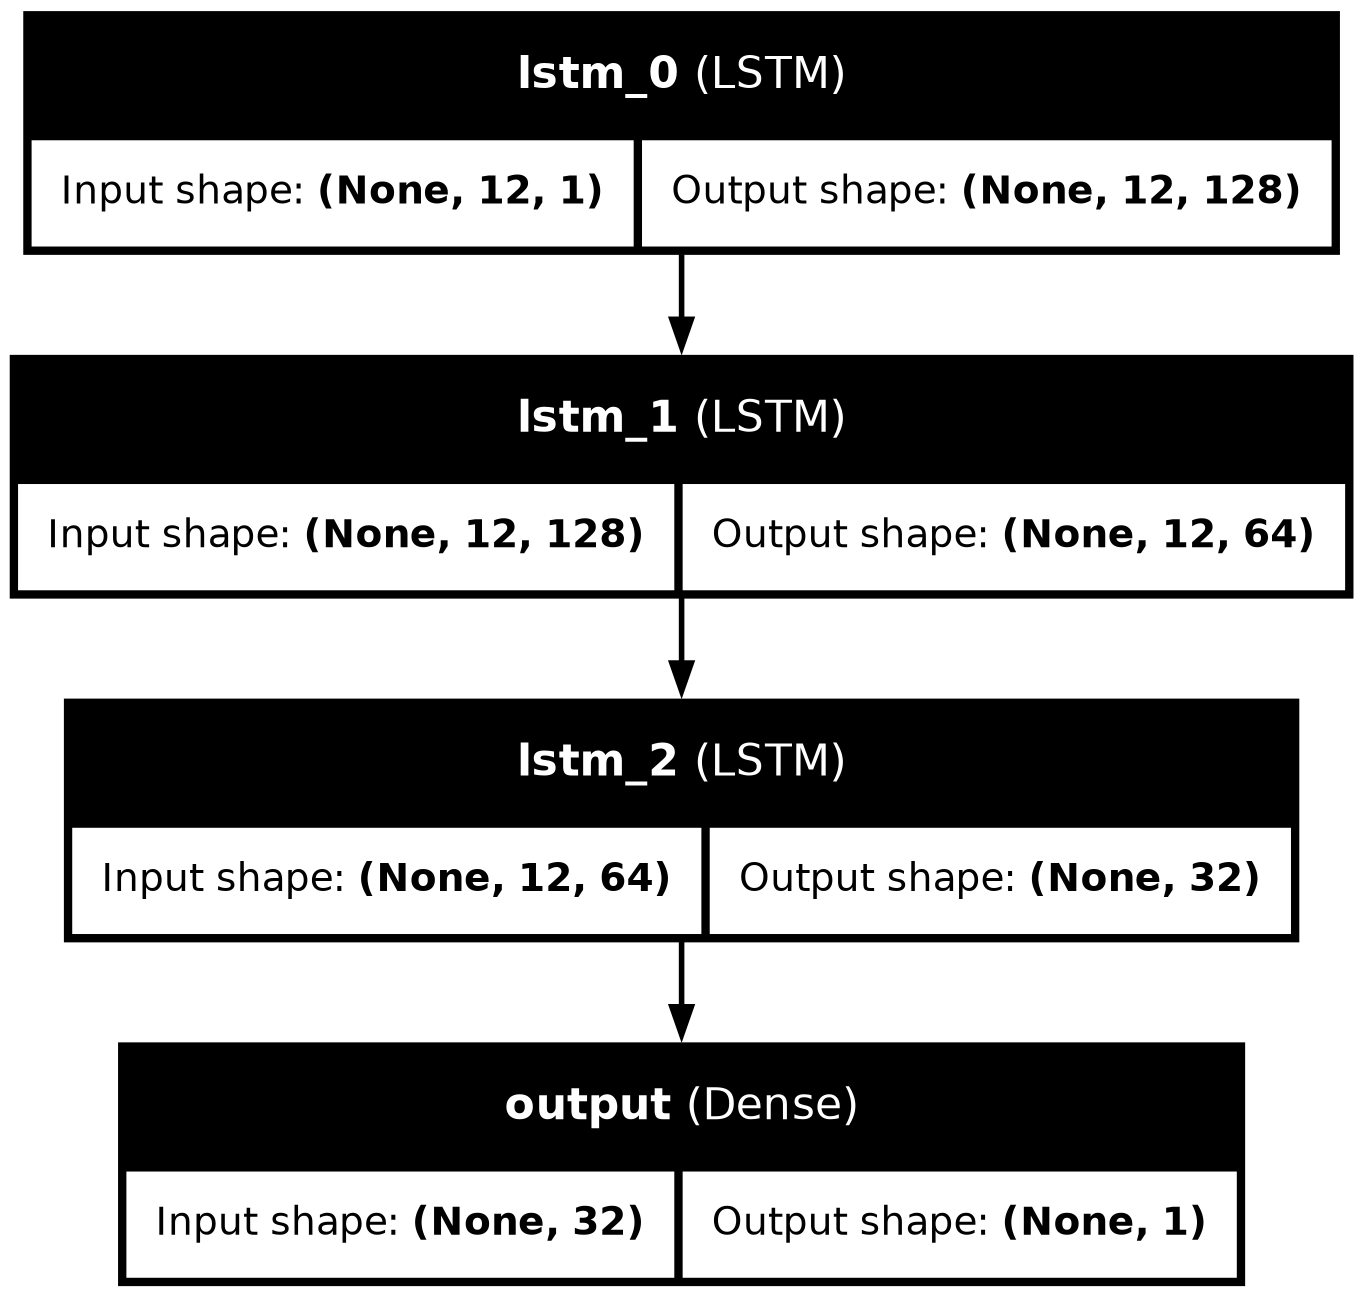

In [25]:
tf.keras.utils.plot_model(
    lstm_model,
    to_file='lstm_architecture.png',
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True
)
Image('lstm_architecture.png')

## GRU-модель
Спрощений аналог LSTM з меншою кількістю параметрів. Архітектура та сама: 128–64–32.

In [26]:
class GRUModel(tf.keras.Sequential):
    def __init__(self, n_neurons, input_dim, sigma=1):
        super(GRUModel, self).__init__()

        weight_initializer = tf.keras.initializers.VarianceScaling(
            seed=7, scale=sigma, mode="fan_avg", distribution="uniform"
        )
        bias_initializer = tf.zeros_initializer()

        self.add(tf.keras.Input(shape=(input_dim, 1), name="input"))

        for i, n in enumerate(n_neurons):
            return_sequences = i < len(n_neurons) - 1  # True для всіх, крім останнього GRU-шару
            self.add(tf.keras.layers.GRU(
                n,
                return_sequences=return_sequences,
                kernel_initializer=weight_initializer,
                bias_initializer=bias_initializer,
                name=f"gru_{i}"
            ))

        self.add(tf.keras.layers.Dense(
            1,
            kernel_initializer=weight_initializer,
            bias_initializer=bias_initializer,
            name="output"
        ))

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 0.1128 - val_loss: 0.0889
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0650 - val_loss: 0.0817
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0613 - val_loss: 0.0808
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0597 - val_loss: 0.0771
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0579 - val_loss: 0.0762
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0542 - val_loss: 0.0727
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0527 - val_loss: 0.0711
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0508 - val_loss: 0.0661
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0475 - val_loss: 0.0600
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0437 - val_loss: 0.0586
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0426 - val_loss: 0.0550
Epoch 12/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step

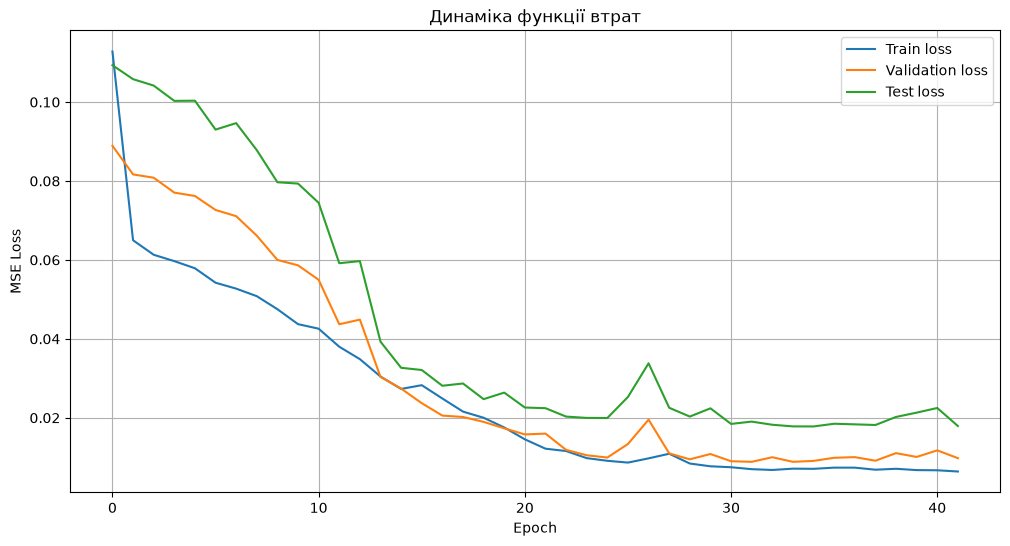

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7f9f69fc7100> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step
MAE: 3.5400
RMSE: 4.7210
MAPE: 3.35%
R²: 0.7837


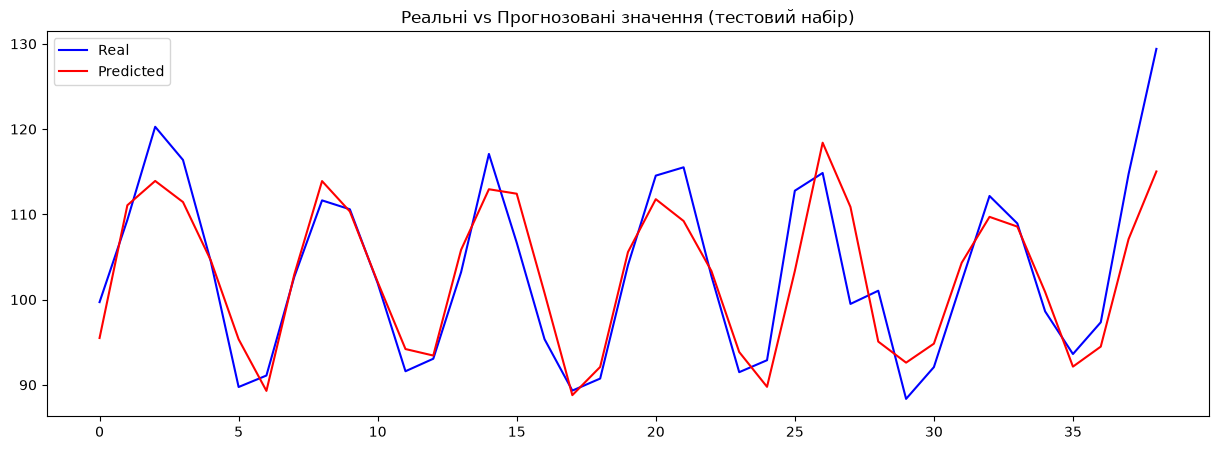

In [27]:
n_neurons = [128, 64, 32]
sigma = 1
epochs = 100
batch_size = 32

gru_model = GRUModel(n_neurons=n_neurons, input_dim=X_train_seq.shape[1], sigma=sigma)
history, test_loss_cb = train_model(gru_model, X_train_seq, y_train, X_val_seq, y_val, X_test_seq, y_test, epochs, batch_size)
y_test_inv, predicted_inv = evaluate_and_plot(gru_model, history, test_loss_cb, X_test_seq, y_test, scaler)

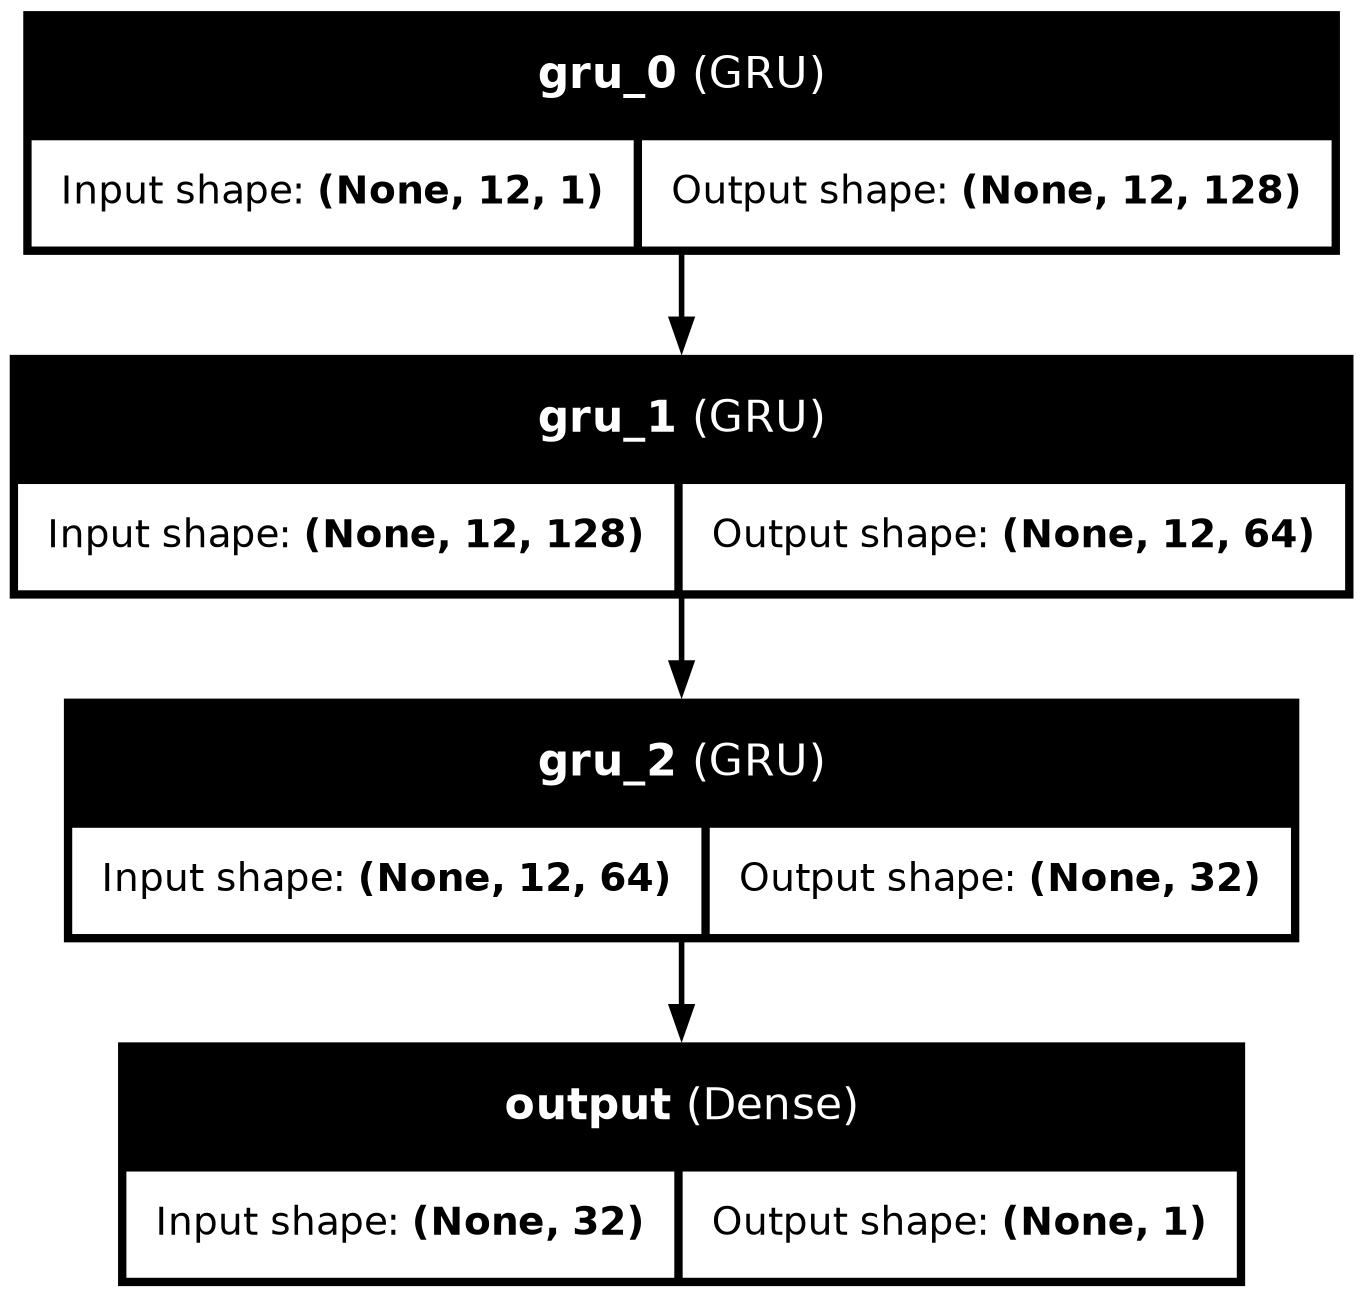

In [28]:
tf.keras.utils.plot_model(
    gru_model,
    to_file='gru_architecture.png',
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True
)
Image('gru_architecture.png')

## Рекурсивна екстраполяція на основі вікон


Кожен новий прогноз додається у вікно як вхід для наступного кроку. Горизонт — 0.5 інтервалу спостереження (198 місяців).

In [29]:
def recursive_forecast(model, last_window, n_steps, is_sequence_model=False):
    window = last_window.copy()
    predictions = []
    for _ in range(n_steps):
        if is_sequence_model:
            model_input = window.reshape(1, -1, 1)
        else:
            model_input = window.reshape(1, -1)
        pred_scaled = model.predict(model_input, verbose=0)[0, 0]
        predictions.append(pred_scaled)
        window = np.append(window[1:], pred_scaled)
    return np.array(predictions)

In [30]:
n_forecast = int(0.5 * len(df))

scaled_series = scaler.transform(series.reshape(-1, 1)).flatten()
last_window = scaled_series[-window_size:]

forecast_index = np.arange(len(df), len(df) + n_forecast)

forecast_dense_scaled = recursive_forecast(dense_model, last_window, n_forecast, is_sequence_model=False)
forecast_lstm_scaled = recursive_forecast(lstm_model, last_window, n_forecast, is_sequence_model=True)
forecast_gru_scaled = recursive_forecast(gru_model, last_window, n_forecast, is_sequence_model=True)

forecast_dense = scaler.inverse_transform(forecast_dense_scaled.reshape(-1, 1))
forecast_lstm = scaler.inverse_transform(forecast_lstm_scaled.reshape(-1, 1))
forecast_gru = scaler.inverse_transform(forecast_gru_scaled.reshape(-1, 1))

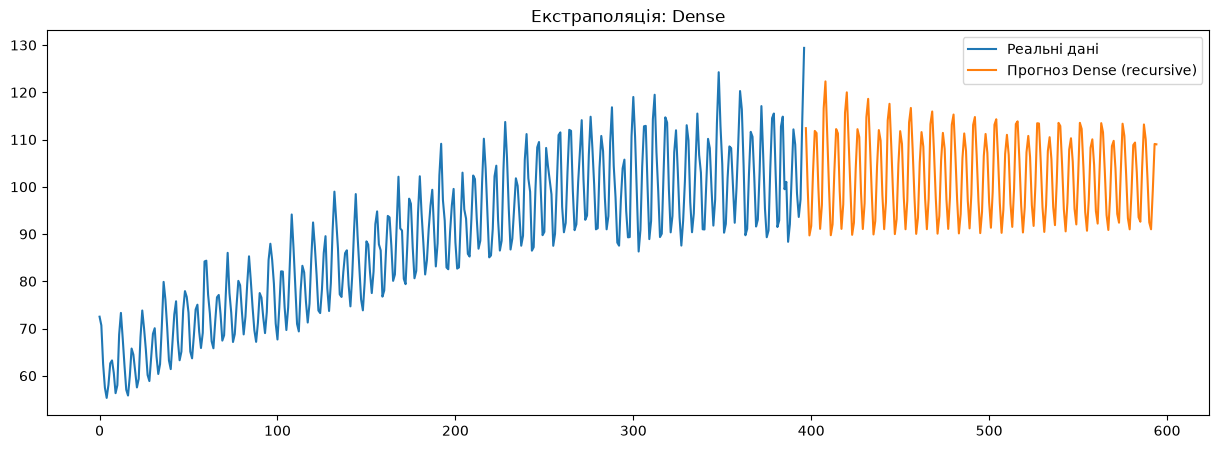

In [31]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['consumption'], label='Реальні дані')
plt.plot(forecast_index, forecast_dense, label='Прогноз Dense (recursive)')
plt.legend()
plt.title('Екстраполяція: Dense')
plt.show()

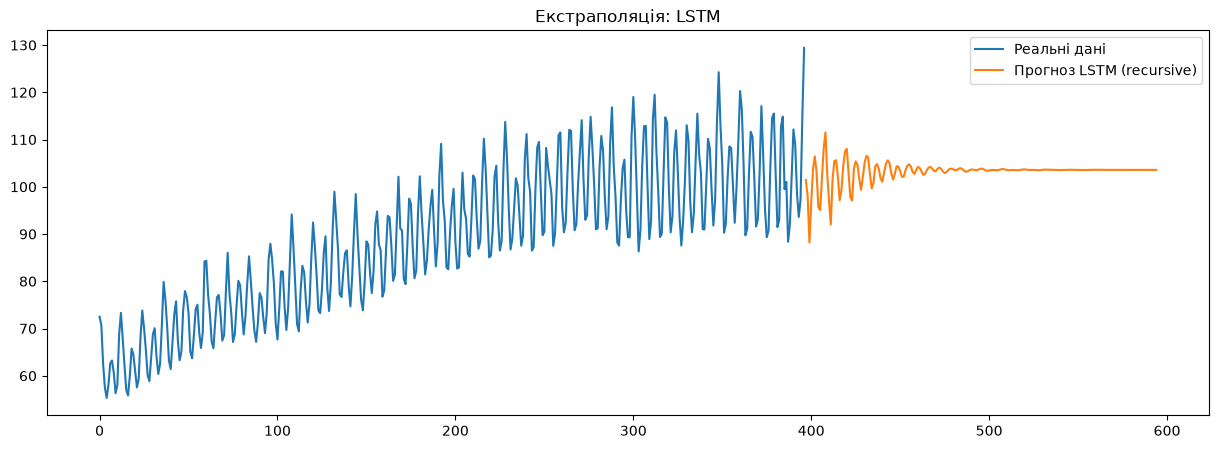

In [32]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['consumption'], label='Реальні дані')
plt.plot(forecast_index, forecast_lstm, label='Прогноз LSTM (recursive)')
plt.legend()
plt.title('Екстраполяція: LSTM')
plt.show()

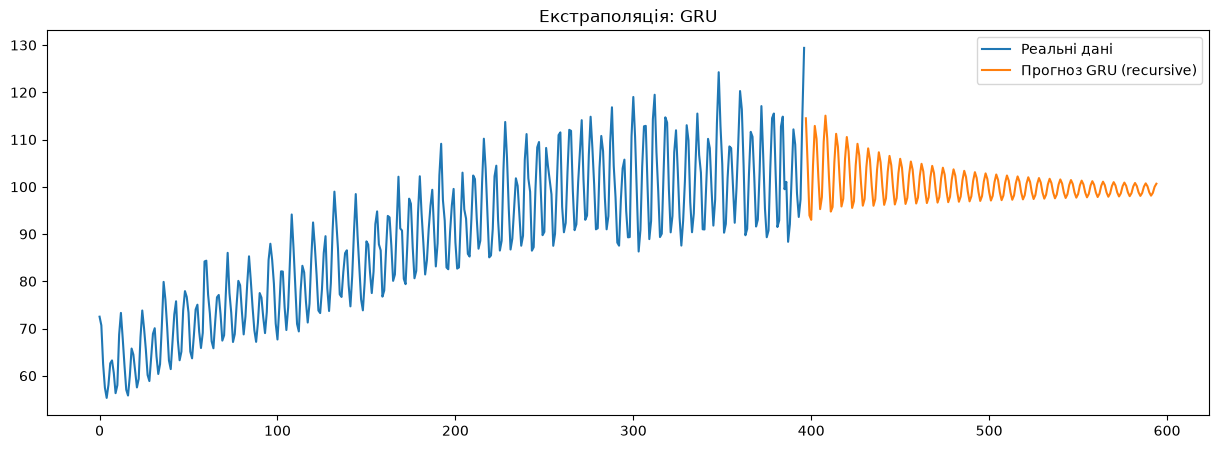

In [33]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['consumption'], label='Реальні дані')
plt.plot(forecast_index, forecast_gru, label='Прогноз GRU (recursive)')
plt.legend()
plt.title('Екстраполяція: GRU')
plt.show()

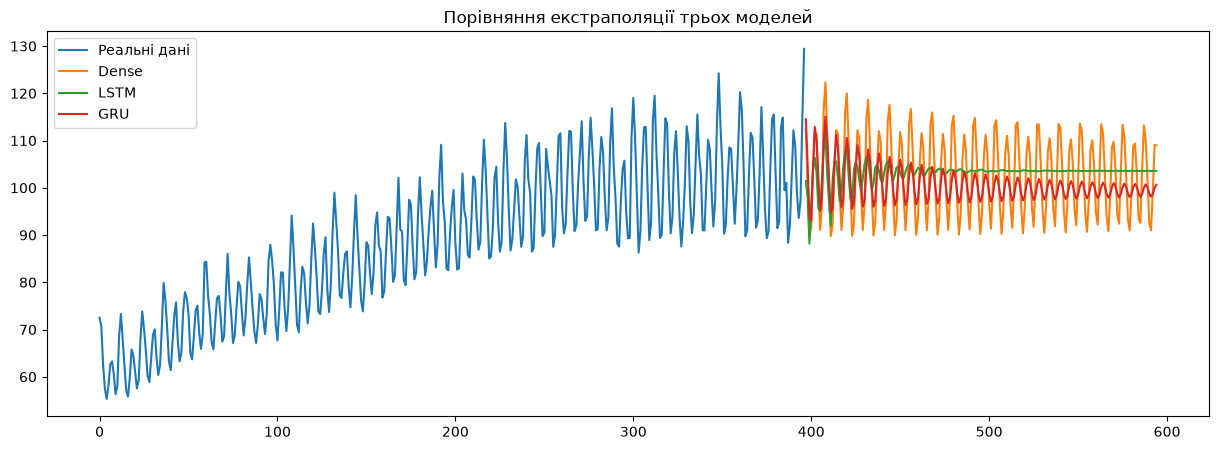

In [34]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['consumption'], label='Реальні дані')
plt.plot(forecast_index, forecast_dense, label='Dense')
plt.plot(forecast_index, forecast_lstm, label='LSTM')
plt.plot(forecast_index, forecast_gru, label='GRU')
plt.legend()
plt.title('Порівняння екстраполяції трьох моделей')
plt.show()

## Порівняння моделей (тестова вибірка)

| Модель | MAE | RMSE | MAPE | R² |
|---|---|---|---|---|
| Dense | 2.82 | 4.01 | 2.64% | 0.844 |
| LSTM | 4.66 | 5.94 | 4.36% | 0.657 |
| GRU | 3.54 | 4.72 | 3.35% | 0.784 |

## Висновки
Найкращу якість на тесті показала Dense-мережа (R² 0.84, MAPE 2.6%), друга — GRU, найгірша — LSTM. Для короткого ряду (≈300 навчальних вікон) проста повнозв'язна мережа виявилася ефективнішою, бо рекурентні моделі мають більше параметрів і їх важче навчити на малій вибірці. При рекурсивній екстраполяції LSTM і GRU швидко «згасають» до майже сталого рівня, а Dense довше зберігає сезонні коливання. Жодна модель не продовжує тренд у довгостроковому прогнозі, тому для довгої екстраполяції варто окремо моделювати тренд (декомпозиція) або працювати з диференційованим рядом.